# Lab 1 – Introduction to Deep Learning (AI & Cybersecurity)
## Task 1 – Preprocessing

Obiettivo: ispezionare il dataset CICIDS2017 (subset), decidere come pulirlo, come dividerlo in train/val/test e quale scaling usare, **motivando ogni scelta con i numeri osservati**.

Struttura del notebook:
1. Setup e caricamento
2. Ispezione (campioni, classi, qualità dei dati)
3. Pulizia (NaN/inf, valori impossibili, duplicati) con conteggi prima/dopo
4. Split train/val/test (stratificato?)
5. Scaling (distribuzioni, code, scelta)
6. Funzione `preprocess()` riutilizzabile (servirà nel Task 3 senza `Destination Port`)
7. Risposte alle domande del Task 1

## 1. Setup

In [30]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

DATA_PATH = "dataset_lab_1.csv"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "/mnt/user-data/uploads/dataset_lab_1.csv"
OUT_DIR = "task1_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("Data:", DATA_PATH)

Data: dataset_lab_1.csv


## 2. Ispezione

In [31]:
df = pd.read_csv(DATA_PATH)
LABEL = "Label"
FEATURES = [c for c in df.columns if c != LABEL]
print(f"Righe: {len(df):,}   Feature: {len(FEATURES)}   Classi: {df[LABEL].nunique()}")
df.head()

Righe: 31,507   Feature: 16   Classi: 4


,Flow Duration,Flow IAT Mean,Fwd PSH Flags,Bwd Packet Length Mean,Bwd Packet Length Max,Flow Bytes/s,Down/Up Ratio,SYN Flag Count,Fwd Packet Length Mean,Fwd IAT Std,Packet Length Mean,Fwd Packet Length Max,Subflow Fwd Packets,Flow Packets/s,Total Fwd Packets,Destination Port,Label
0,303376,30337.600000,0,749.4,1448,12743.263,0,0,19.833334,98776.15,322.16666,119,6,36.258636,6,443,Benign
1,117,117.000000,0,0.0,0,0.000,1,0,0.000000,0.00,0.00000,0,1,17094.018000,1,52631,Benign
2,142,142.000000,0,0.0,0,84507.040,0,0,6.000000,0.00,6.00000,6,2,14084.507000,2,80,Benign
3,191,63.666668,0,52.0,52,921465.940,1,0,36.000000,0.00,42.40000,36,2,20942.408000,2,53,Benign
4,4,4.000000,0,0.0,0,3000000.000,0,0,6.000000,0.00,6.00000,6,2,500000.000000,2,49467,Benign


,n,%
Label,,
Benign,20000,63.48
DoS Hulk,5000,15.87
PortScan,5000,15.87
Brute Force,1507,4.78


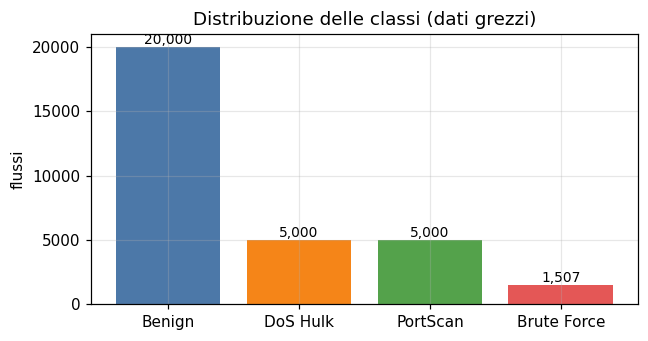

In [32]:
counts = df[LABEL].value_counts()
summary = pd.DataFrame({"n": counts, "%": (counts / len(df) * 100).round(2)})
display(summary)

fig, ax = plt.subplots(figsize=(6, 3.2))
bars = ax.bar(summary.index, summary["n"], color=["#4c78a8", "#f58518", "#54a24b", "#e45756"])
for b, n in zip(bars, summary["n"]):
    ax.text(b.get_x() + b.get_width() / 2, n, f"{n:,}", ha="center", va="bottom", fontsize=9)
ax.set_title("Distribuzione delle classi (dati grezzi)"); ax.set_ylabel("flussi")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_class_balance_raw.png"); plt.show()

### 2.1 Controlli di qualità

In [33]:
rate_cols = ["Flow Bytes/s", "Flow Packets/s"]
X_raw = df[FEATURES]

n_nan_rows = df.isna().any(axis=1).sum()
inf_mask = np.isinf(df[FEATURES]).any(axis=1)
nan_inf_mask = df[FEATURES].replace([np.inf, -np.inf], np.nan).isna().any(axis=1)
neg_mask = (df[FEATURES] < 0).any(axis=1)
dup_mask = df.duplicated()

print("NaN per colonna:", df.isna().sum()[df.isna().sum() > 0].to_dict())
print("Righe con NaN                 :", n_nan_rows)
print("Righe con +/-inf              :", inf_mask.sum(), "  (per colonna:", np.isinf(df[FEATURES]).sum()[np.isinf(df[FEATURES]).sum() > 0].to_dict(), ")")
print("Righe con NaN o inf (unione)  :", nan_inf_mask.sum())
print("Righe con valori negativi     :", neg_mask.sum(), "  (colonne:", (df[FEATURES] < 0).sum()[(df[FEATURES] < 0).sum() > 0].to_dict(), ")")
print("Righe duplicate (copie extra) :", dup_mask.sum())
print("Colonne costanti              :", [c for c in FEATURES if df[c].nunique() <= 1])

print("\nColonne identiche tra loro:")
for i, a in enumerate(FEATURES):
    for b in FEATURES[i + 1:]:
        if (df[a] == df[b]).all():
            print(f"  {a}  ==  {b}")

q = pd.DataFrame({
    "NaN/inf": df[nan_inf_mask][LABEL].value_counts(),
    "negativi": df[neg_mask][LABEL].value_counts(),
    "duplicati (copie extra)": df[dup_mask][LABEL].value_counts(),
}).fillna(0).astype(int)
q["n_classe"] = counts
q["% dup sulla classe"] = (q["duplicati (copie extra)"] / q["n_classe"] * 100).round(1)
print("\nProblemi per classe:")
display(q)

NaN per colonna: {'Flow Bytes/s': 20}
Righe con NaN                 : 20
Righe con +/-inf              : 27   (per colonna: {'Flow Bytes/s': 7, 'Flow Packets/s': 27} )
Righe con NaN o inf (unione)  : 27
Righe con valori negativi     : 2   (colonne: {'Flow Duration': 2, 'Flow IAT Mean': 2, 'Flow Bytes/s': 2, 'Flow Packets/s': 2} )
Righe duplicate (copie extra) : 2111
Colonne costanti              : []

Colonne identiche tra loro:
  Fwd PSH Flags  ==  SYN Flag Count
  Subflow Fwd Packets  ==  Total Fwd Packets

Problemi per classe:


,NaN/inf,negativi,duplicati (copie extra),n_classe,% dup sulla classe
Label,,,,,
Benign,8,2,750,20000,3.8
Brute Force,0,0,80,1507,5.3
DoS Hulk,18,0,1131,5000,22.6
PortScan,1,0,150,5000,3.0


**Lettura dei risultati.**
- Gli `inf` non sono visti da `isna()`: vanno convertiti in NaN prima di decidere. Le 20 righe con NaN in `Flow Bytes/s` sono incluse nelle 27 righe con valori non finiti: tutte e 27 hanno `Flow Duration` = 0, quindi i rate (byte/s, pacchetti/s) sono indefiniti per divisione per zero.
- I NaN/inf sono concentrati in **DoS Hulk** (flussi brevissimi); i 2 valori negativi (durata/IAT/rate = -1 o negativi) sono fisicamente impossibili.
- I duplicati pesano in modo diverso per classe: DoS Hulk ne ha di più in valore assoluto e in percentuale.
- Due coppie di colonne sono identiche (`Fwd PSH Flags`=`SYN Flag Count`, `Subflow Fwd Packets`=`Total Fwd Packets`): informazione ridondante, non dannosa per una FFNN ma da dichiarare.

### 2.2 `Destination Port` per classe (osservazione utile per il Task 3)

In [34]:
port_info = df.groupby(LABEL)["Destination Port"].agg(
    n_porte_distinte="nunique",
    porta_piu_frequente=lambda s: s.value_counts().index[0],
    quota_porta_top=lambda s: round(s.value_counts().iloc[0] / len(s), 3),
)
display(port_info)

,n_porte_distinte,porta_piu_frequente,quota_porta_top
Label,,,
Benign,3603,53,0.426
Brute Force,1,80,1.000
DoS Hulk,1,80,1.000
PortScan,995,5631,0.003


## 3. Pulizia

**Decisioni**
1. **`inf` → NaN, poi eliminazione delle righe con NaN.** Sono 27 righe (0,09%), i valori mancanti riguardano rate calcolati su flussi di durata nulla: non c'è un valore "vero" da ricostruire, e imputare (media/mediana) inventerebbe un rate plausibile per flussi che in realtà sono degeneri. Con una perdita così piccola l'eliminazione è la scelta più semplice e onesta. Controllo sotto che non svuoti nessuna classe.
2. **Eliminazione delle righe con valori negativi** (2 righe): durata, IAT e rate negativi non hanno significato fisico, sono errori di misura.
3. **Eliminazione dei duplicati *prima* dello split.** Righe identiche potrebbero finire sia in train sia in validation/test: il modello le "ricorderebbe" e le metriche risulterebbero gonfiate (data leakage). *Nota:* nel Task 3 rivaluteremo questa scelta, perché senza la porta la de-duplicazione cambia in modo molto diverso le classi. Qui registro i conteggi per classe in ogni passo.
4. **Colonne ridondanti:** le tengo (una FFNN non ne soffre in modo rilevante e così il lab resta confrontabile), ma le dichiaro.

In [35]:
def clean(df_in, verbose=True):
    log = {}
    d = df_in.copy()
    log["0_grezzo"] = d[LABEL].value_counts()

    d[FEATURES] = d[FEATURES].replace([np.inf, -np.inf], np.nan)
    d = d.dropna()
    log["1_dopo_NaN/inf"] = d[LABEL].value_counts()

    d = d[~(d[FEATURES] < 0).any(axis=1)]
    log["2_dopo_negativi"] = d[LABEL].value_counts()

    d = d.drop_duplicates()
    log["3_dopo_duplicati"] = d[LABEL].value_counts()

    table = pd.DataFrame(log).fillna(0).astype(int)
    table.loc["TOTALE"] = table.sum()
    if verbose:
        display(table)
    return d.reset_index(drop=True), table

df_clean, clean_table = clean(df)
n0, n1 = clean_table.loc["TOTALE", "0_grezzo"], clean_table.loc["TOTALE", "3_dopo_duplicati"]
print(f"Campioni PRIMA della pulizia: {n0:,}   DOPO: {n1:,}   (rimossi {n0-n1:,} = {100*(n0-n1)/n0:.1f}%)")

,0_grezzo,1_dopo_NaN/inf,2_dopo_negativi,3_dopo_duplicati
Label,,,,
Benign,20000,19992,19990,19240
Brute Force,1507,1507,1507,1427
DoS Hulk,5000,4982,4982,3868
PortScan,5000,4999,4999,4849
TOTALE,31507,31480,31478,29384


Campioni PRIMA della pulizia: 31,507   DOPO: 29,384   (rimossi 2,123 = 6.7%)


In [36]:
rows = []
for cls in clean_table.index[:-1]:
    a, b = clean_table.loc[cls, "0_grezzo"], clean_table.loc[cls, "3_dopo_duplicati"]
    rows.append({"classe": cls, "prima": a, "dopo": b, "perso %": round(100 * (a - b) / a, 1)})
display(pd.DataFrame(rows).set_index("classe"))

,prima,dopo,perso %
classe,,,
Benign,20000,19240,3.8
Brute Force,1507,1427,5.3
DoS Hulk,5000,3868,22.6
PortScan,5000,4849,3.0


## 4. Split train / validation / test

**Scelta:** 70 % train / 15 % validation / 15 % test, **stratificato** sulla `Label`, seed fisso.

**Perché stratificare.** Brute Force è la classe rara (circa il 5 %). Senza stratificazione la sua quota in validation/test dipende dal caso: verifico qui sotto quanto può oscillare.

In [37]:
y_all = df_clean[LABEL]
idx = np.arange(len(df_clean))

# Esperimento: quanto varia il numero di Brute Force nel validation set senza stratificare?
bf_counts = []
for s in range(200):
    tr, tmp = train_test_split(idx, test_size=0.30, random_state=s)
    va, te = train_test_split(tmp, test_size=0.50, random_state=s)
    bf_counts.append((y_all.iloc[va] == "Brute Force").sum())
bf_counts = np.array(bf_counts)

tr, tmp = train_test_split(idx, test_size=0.30, random_state=SEED, stratify=y_all)
va, te = train_test_split(tmp, test_size=0.50, random_state=SEED, stratify=y_all.iloc[tmp])
print(f"Brute Force nel validation SENZA stratificazione (200 seed): min={bf_counts.min()}, max={bf_counts.max()}, media={bf_counts.mean():.1f}")
print(f"Brute Force nel validation CON stratificazione           : {(y_all.iloc[va]=='Brute Force').sum()}")

split_tbl = pd.DataFrame({
    "train": y_all.iloc[tr].value_counts(),
    "val": y_all.iloc[va].value_counts(),
    "test": y_all.iloc[te].value_counts(),
})
split_pct = (split_tbl / split_tbl.sum() * 100).round(2)
split_tbl.loc["TOTALE"] = split_tbl.sum()
print("\nConteggi per partizione:"); display(split_tbl)
print("Percentuali per classe dentro ogni partizione:"); display(split_pct)

Brute Force nel validation SENZA stratificazione (200 seed): min=178, max=252, media=216.1
Brute Force nel validation CON stratificazione           : 214

Conteggi per partizione:


,train,val,test
Label,,,
Benign,13467,2886,2887
PortScan,3394,728,727
DoS Hulk,2708,580,580
Brute Force,999,214,214
TOTALE,20568,4408,4408


Percentuali per classe dentro ogni partizione:


,train,val,test
Label,,,
Benign,65.48,65.47,65.49
PortScan,16.50,16.52,16.49
DoS Hulk,13.17,13.16,13.16
Brute Force,4.86,4.85,4.85


## 5. Scaling

Prima di scegliere guardo le distribuzioni **sul solo train set** (qualunque statistica usata per decidere o per scalare deve venire dal train).

In [38]:
Xtr_raw = df_clean.loc[tr, FEATURES]

desc = Xtr_raw.describe(percentiles=[.5, .99]).T[["min", "50%", "99%", "max"]]
desc["max/mediana"] = (desc["max"] / desc["50%"].replace(0, np.nan)).round(1)
desc["skew"] = Xtr_raw.skew().round(1)
desc["n_valori_distinti"] = Xtr_raw.nunique()
display(desc.sort_values("skew", ascending=False))

,min,50%,99%,max,max/mediana,skew,n_valori_distinti
Subflow Fwd Packets,1.000000,2.000000,5.000000e+01,3.141000e+03,1570.5,64.4,139
Total Fwd Packets,1.000000,2.000000,5.000000e+01,3.141000e+03,1570.5,64.4,139
Flow Bytes/s,0.000000,5250.039350,1.233333e+07,2.070000e+09,394282.8,44.3,13426
Fwd Packet Length Mean,0.000000,34.000000,3.731191e+02,2.361160e+03,69.4,10.7,2960
Fwd Packet Length Max,0.000000,37.000000,2.012990e+03,1.163200e+04,314.4,8.5,1086
Flow IAT Mean,0.500000,10856.166500,1.871918e+07,1.140000e+08,10500.9,7.4,12663
Flow Packets/s,0.017486,118.779997,7.500000e+05,3.000000e+06,25256.8,7.3,12755
Fwd PSH Flags,0.000000,0.000000,1.000000e+00,1.000000e+00,NaN,4.7,2
SYN Flag Count,0.000000,0.000000,1.000000e+00,1.000000e+00,NaN,4.7,2
Bwd Packet Length Max,0.000000,70.000000,8.688000e+03,1.159500e+04,165.6,2.5,1102


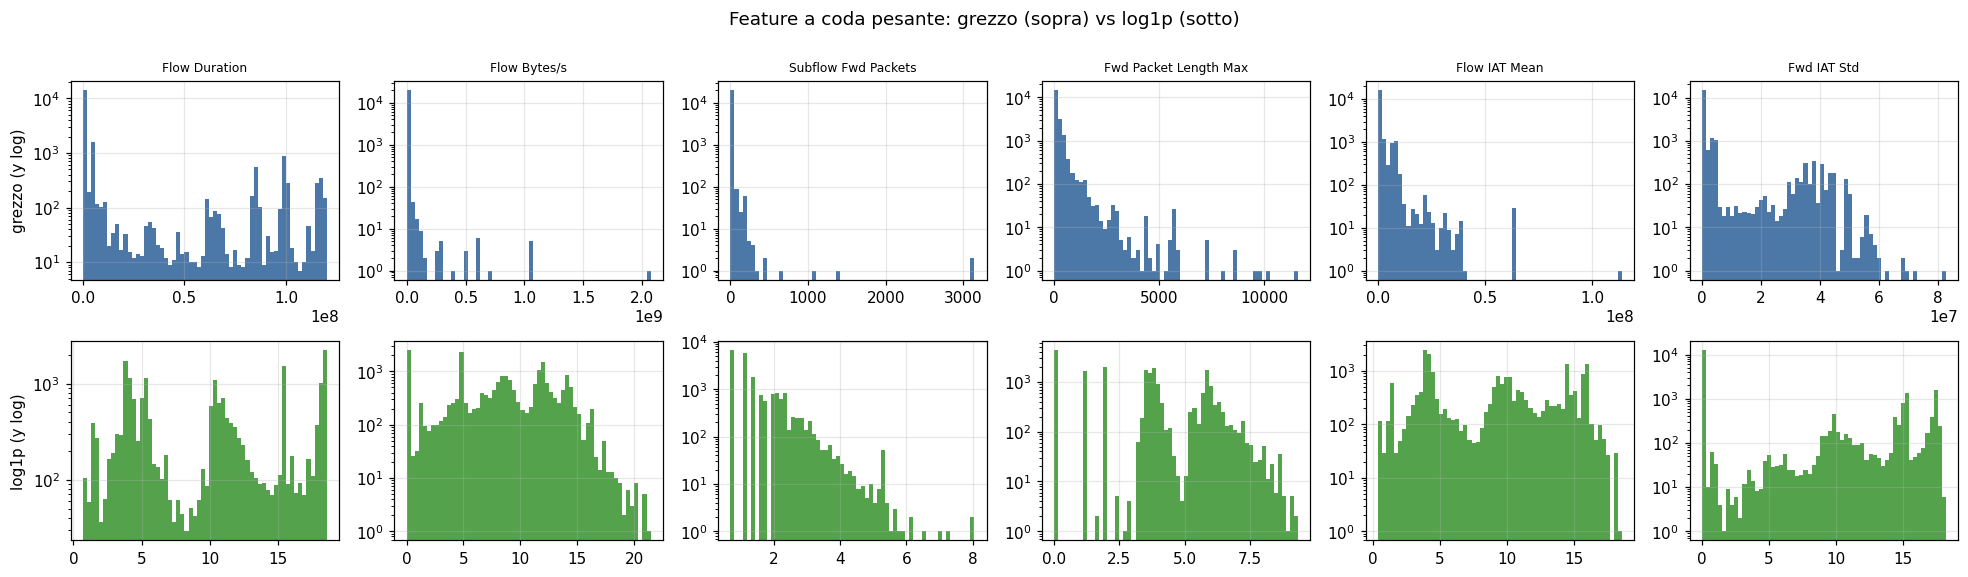

In [39]:
BINARY_OR_SMALL = ["Fwd PSH Flags", "SYN Flag Count", "Down/Up Ratio"]
CATEGORICAL_LIKE = ["Destination Port"]
LOG_FEATURES = [c for c in FEATURES if c not in BINARY_OR_SMALL + CATEGORICAL_LIKE]

heavy = ["Flow Duration", "Flow Bytes/s", "Subflow Fwd Packets", "Fwd Packet Length Max", "Flow IAT Mean", "Fwd IAT Std"]
fig, axes = plt.subplots(2, len(heavy), figsize=(3.0 * len(heavy), 5.2))
for j, c in enumerate(heavy):
    axes[0, j].hist(Xtr_raw[c], bins=60, color="#4c78a8")
    axes[0, j].set_yscale("log"); axes[0, j].set_title(c, fontsize=8)
    axes[1, j].hist(np.log1p(Xtr_raw[c]), bins=60, color="#54a24b")
    axes[1, j].set_yscale("log")
axes[0, 0].set_ylabel("grezzo (y log)"); axes[1, 0].set_ylabel("log1p (y log)")
plt.suptitle("Feature a coda pesante: grezzo (sopra) vs log1p (sotto)", y=1.0)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_distributions_raw_vs_log.png"); plt.show()

**Confronto quantitativo tra tre strategie.** Misuro, per ogni strategia (fit sul train), quanti valori del train finiscono oltre ±5 deviazioni (o ±5 volte l'IQR per il Robust): più sono, più la scala è dominata dagli outlier.

In [40]:
def frac_extreme(Z, thr=5.0):
    return float((np.abs(Z) > thr).mean())

def make_log(df_x):
    d = df_x.copy()
    d[LOG_FEATURES] = np.log1p(d[LOG_FEATURES])
    return d

Z_std = StandardScaler().fit(Xtr_raw).transform(Xtr_raw)
Z_rob = RobustScaler().fit(Xtr_raw).transform(Xtr_raw)
Xtr_log = make_log(Xtr_raw)
Z_logstd = StandardScaler().fit(Xtr_log).transform(Xtr_log)

cmp_tbl = pd.DataFrame({
    "Standard": [frac_extreme(Z_std), np.abs(Z_std).max()],
    "Robust": [frac_extreme(Z_rob), np.abs(Z_rob).max()],
    "log1p + Standard": [frac_extreme(Z_logstd), np.abs(Z_logstd).max()],
}, index=["% valori con |z|>5", "max |z|"]).T
cmp_tbl["% valori con |z|>5"] = (cmp_tbl["% valori con |z|>5"] * 100).round(2)
cmp_tbl["max |z|"] = cmp_tbl["max |z|"].round(1)
display(cmp_tbl)

skew_cmp = pd.DataFrame({"skew grezzo": Xtr_raw[LOG_FEATURES].skew(), "skew dopo log1p": Xtr_log[LOG_FEATURES].skew()}).round(1)
display(skew_cmp)

,% valori con |z|>5,max |z|
Standard,0.23,85.2
Robust,8.19,13956.6
log1p + Standard,0.05,10.2


,skew grezzo,skew dopo log1p
Flow Duration,1.8,0.2
Flow IAT Mean,7.4,0.1
Bwd Packet Length Mean,2.1,-0.0
Bwd Packet Length Max,2.5,0.2
Flow Bytes/s,44.3,-0.3
Fwd Packet Length Mean,10.7,-0.4
Fwd IAT Std,2.5,0.7
Packet Length Mean,2.0,-0.1
Fwd Packet Length Max,8.5,-0.0
Subflow Fwd Packets,64.4,1.7


**Scelta: `log1p` sulle feature continue non negative + `StandardScaler`** (fit solo sul train).

- Le feature di dimensione/tempo/rate hanno code lunghe che spaziano su più ordini di grandezza (es. `Flow Duration`: mediana ~3·10⁴, massimo ~1,2·10⁸; `Flow Bytes/s`: skew ~44 e massimo ~2·10⁹; `Subflow Fwd Packets`: skew ~64 sul train, 157 sull'intero dataset perché il valore estremo è finito fuori dal train). Con un `StandardScaler` puro, media e deviazione standard sono trascinate da pochi flussi enormi: pochi outlier restano a decine di deviazioni (max |z| = 85 con `StandardScaler` puro contro 10 con `log1p` + `StandardScaler`) e il grosso dei dati viene compresso in una fascia stretta, il che destabilizza il training.
- Il `RobustScaler` (mediana/IQR) va peggio: **8,2 % dei valori finisce oltre |z| = 5 e il massimo arriva a ~14.000**, perché dividere per un IQR molto piccolo (molte feature hanno quasi tutti zeri o valori piccoli) amplifica gli outlier.
- `log1p` comprime le code mantenendo l'ordinamento (e gestisce gli zeri, a differenza di `log`); dopo la trasformazione gli skew calano di molto (la più ostica resta `Subflow Fwd Packets`/`Total Fwd Packets`, da 64 a 1,7: sono conteggi molto concentrati su pochi valori) e lo `StandardScaler` finale è ben condizionato. È ammissibile perché dopo la pulizia nessuna feature è negativa.
- **Non** applico `log1p` a: `Fwd PSH Flags` e `SYN Flag Count` (binarie), `Down/Up Ratio` (piccolo intero 0–10), `Destination Port` (identificatore, non una quantità: il log non ha significato). Queste ricevono solo `StandardScaler`.

### 5.1 Perché il scaler va fittato solo sul train

Se si calcolano media e deviazione standard su **tutti** i dati, le statistiche di validation e test entrano nella trasformazione: il modello "vede" informazioni che nel mondo reale non avrebbe. Sotto: l'effetto sui parametri stimati. È piccolo qui (nelle feature più colpite lo scarto delle medie è sotto 0,01 deviazioni standard) perché il dataset è grande e lo split è stratificato, ma il principio resta: la stima delle prestazioni su val/test non è più indipendente dal preprocessing. Con code pesanti e pochi outlier nel test il fit su tutto può cambiare in modo visibile la scala.

In [41]:
Xall_log = make_log(df_clean[FEATURES])
sc_train = StandardScaler().fit(Xtr_log)
sc_all = StandardScaler().fit(Xall_log)

leak = pd.DataFrame({
    "media (train)": sc_train.mean_, "media (tutti)": sc_all.mean_,
    "std (train)": sc_train.scale_, "std (tutti)": sc_all.scale_,
}, index=FEATURES)
leak["Δ media / std"] = ((leak["media (tutti)"] - leak["media (train)"]) / leak["std (train)"]).round(4)
display(leak.round(4).sort_values("Δ media / std", key=np.abs, ascending=False).head(8))

,media (train),media (tutti),std (train),std (tutti),Δ media / std
Flow Bytes/s,8.1443,8.1102,4.6477,4.6564,-0.0073
Fwd Packet Length Mean,2.7213,2.7087,1.7513,1.7557,-0.0072
Fwd PSH Flags,0.0405,0.0394,0.1972,0.1945,-0.0059
SYN Flag Count,0.0405,0.0394,0.1972,0.1945,-0.0059
Fwd Packet Length Max,3.2467,3.2332,2.2856,2.2893,-0.0059
Packet Length Mean,3.4332,3.4221,2.1698,2.1796,-0.0051
Bwd Packet Length Max,3.9286,3.9187,2.9183,2.9232,-0.0034
Bwd Packet Length Mean,3.5902,3.5834,2.5237,2.5307,-0.0027


## 6. Funzione `preprocess()` riutilizzabile

Incapsula tutta la pipeline (pulizia → split stratificato → log1p → StandardScaler fit sul train). Nel Task 3 basterà chiamarla con `drop_port=True`.

In [42]:
def preprocess(df_in, drop_port=False, seed=SEED, dedup=True, test_size=0.15, val_size=0.15, verbose=True):
    d = df_in.copy()
    if drop_port:
        d = d.drop(columns="Destination Port")
    feats = [c for c in d.columns if c != LABEL]

    # pulizia
    d[feats] = d[feats].replace([np.inf, -np.inf], np.nan)
    d = d.dropna()
    d = d[~(d[feats] < 0).any(axis=1)]
    if dedup:
        d = d.drop_duplicates()
    d = d.reset_index(drop=True)

    # split stratificato
    classes = sorted(d[LABEL].unique())
    cls2id = {c: i for i, c in enumerate(classes)}
    y = d[LABEL].map(cls2id).values
    i_tr, i_tmp = train_test_split(np.arange(len(d)), test_size=val_size + test_size, random_state=seed, stratify=y)
    i_va, i_te = train_test_split(i_tmp, test_size=test_size / (val_size + test_size), random_state=seed, stratify=y[i_tmp])

    # log1p + scaler (fit SOLO sul train)
    log_feats = [c for c in feats if c in LOG_FEATURES]
    def tf(ix):
        x = d.loc[ix, feats].copy()
        x[log_feats] = np.log1p(x[log_feats])
        return x
    X_tr, X_va, X_te = tf(i_tr), tf(i_va), tf(i_te)
    scaler = StandardScaler().fit(X_tr)
    out = {
        "X_train": scaler.transform(X_tr).astype("float32"), "y_train": y[i_tr],
        "X_val": scaler.transform(X_va).astype("float32"), "y_val": y[i_va],
        "X_test": scaler.transform(X_te).astype("float32"), "y_test": y[i_te],
        "features": feats, "classes": classes, "scaler": scaler, "log_features": log_feats,
        "class_counts_clean": d[LABEL].value_counts().to_dict(),
    }
    if verbose:
        print(f"drop_port={drop_port} dedup={dedup}  |  campioni puliti: {len(d):,}  train/val/test: {len(i_tr):,}/{len(i_va):,}/{len(i_te):,}")
        print("classi:", cls2id)
        print("conteggi dopo pulizia:", out["class_counts_clean"])
    return out

data = preprocess(df, drop_port=False)
for k in ["X_train", "X_val", "X_test"]:
    print(k, data[k].shape, "mean≈", round(float(data[k].mean()), 3) if k == "X_train" else "", "std≈", round(float(data[k].std()), 3) if k == "X_train" else "")

drop_port=False dedup=True  |  campioni puliti: 29,384  train/val/test: 20,568/4,408/4,408
classi: {'Benign': 0, 'Brute Force': 1, 'DoS Hulk': 2, 'PortScan': 3}
conteggi dopo pulizia: {'Benign': 19240, 'PortScan': 4849, 'DoS Hulk': 3868, 'Brute Force': 1427}
X_train (20568, 16) mean≈ 0.0 std≈ 1.0
X_val (4408, 16) mean≈  std≈ 
X_test (4408, 16) mean≈  std≈ 


In [43]:
# Controlli di sanità: nessuna riga in comune tra partizioni, nessun NaN, train ~ media 0 / std 1
import hashlib
def rows_hash(X): return {hashlib.md5(r.tobytes()).hexdigest() for r in X}
h_tr, h_va, h_te = rows_hash(data["X_train"]), rows_hash(data["X_val"]), rows_hash(data["X_test"])
print("righe coincidenti (a precisione float32) train∩val:", len(h_tr & h_va), "  train∩test:", len(h_tr & h_te), "  val∩test:", len(h_va & h_te))
print("Nota: i duplicati esatti sono già stati rimossi; eventuali coincidenze residue sono quasi-duplicati che la de-duplicazione esatta non intercetta (impatto trascurabile su ~8.800 righe tra val e test).")
print("NaN/inf presenti:", any(not np.isfinite(data[k]).all() for k in ["X_train", "X_val", "X_test"]))

np.savez_compressed(f"{OUT_DIR}/task1_preprocessed_with_port.npz",
    X_train=data["X_train"], y_train=data["y_train"], X_val=data["X_val"], y_val=data["y_val"],
    X_test=data["X_test"], y_test=data["y_test"], features=np.array(data["features"]), classes=np.array(data["classes"]))
clean_table.to_csv(f"{OUT_DIR}/cleaning_counts_by_class.csv")
print("Salvati i file in", OUT_DIR)

righe coincidenti (a precisione float32) train∩val: 0   train∩test: 3   val∩test: 1
Nota: i duplicati esatti sono già stati rimossi; eventuali coincidenze residue sono quasi-duplicati che la de-duplicazione esatta non intercetta (impatto trascurabile su ~8.800 righe tra val e test).
NaN/inf presenti: False
Salvati i file in task1_outputs


## 7. Risposte alle domande del Task 1

**Cosa ho visto (Inspect).** 31.507 flussi, 16 feature numeriche, 4 classi: Benign 20.000 (63,5 %), DoS Hulk 5.000 (15,9 %), PortScan 5.000 (15,9 %), Brute Force 1.507 (4,8 %). Problemi di qualità: 20 NaN in `Flow Bytes/s` e 27 righe con `inf` (insieme 27 righe, in gran parte DoS Hulk), 2 righe con valori negativi (Benign), 2.111 duplicati, e due coppie di colonne identiche. Nessuna colonna costante.

**Q: Quanti campioni prima e dopo la pulizia?** 31.507 → 31.478 (dopo NaN/inf e negativi, −29) → **29.384** dopo la de-duplicazione (−2.123 in totale, circa 6,7 %). Per classe dopo la pulizia: Benign 19.240, PortScan 4.849, DoS Hulk 3.868, Brute Force 1.427.

**NaN e duplicati: cosa ho deciso.** NaN/inf: eliminati (perdita 0,09 %, valori non ricostruibili perché derivano da flussi a durata nulla; un'imputazione inventerebbe rate plausibili per flussi degeneri). Negativi: eliminati (impossibili fisicamente). Duplicati: eliminati prima dello split per evitare leakage tra partizioni; la scelta sarà rivalutata nel Task 3 alla luce dell'effetto sulle classi.

**Q: Lo split deve essere stratificato?** Sì. Brute Force è circa il 5 % e senza stratificazione il numero di suoi campioni nel validation set oscilla da seed a seed (vedi esperimento sopra), rendendo instabili le metriche proprio sulla classe più difficile. Con la stratificazione ogni partizione conserva le proporzioni originali. Split scelto: 70/15/15, seed 42.

**Q: Dove si fitta lo scaler e cosa va storto se si fitta su tutti i dati?** Sul solo train; val e test vengono solo trasformati con quei parametri. Fittarlo su tutto fa entrare informazione di val/test nel preprocessing (data leakage): la stima di generalizzazione diventa ottimistica e non rappresenta più il deployment, dove i dati nuovi non sono disponibili al momento del fit. Qui la differenza numerica è piccola (tabella sopra), ma il principio è metodologico.

**Q: Quale scaling e perché? Come hanno influito gli outlier?** `log1p` sulle feature continue non negative (tutte tranne i flag binari, `Down/Up Ratio` e `Destination Port`) seguito da `StandardScaler` fittato sul train. Le feature hanno code pesanti su più ordini di grandezza (skew fino a ~64 sul train, rapporti max/mediana fino a ~4·10⁵): con `StandardScaler` puro gli outlier dominano media e deviazione standard e comprimono il grosso dei dati; con `RobustScaler` il grosso dei dati è ben scalato ma gli outlier restano estremi. `log1p` comprime le code, gestisce gli zeri, e riduce sia la quota di valori estremi (da 0,23 % a 0,05 % oltre |z| = 5) sia il massimo |z| (da 85 a 10), contro l'8,2 % e ~14.000 del `RobustScaler` (confronto quantitativo sopra).

**Da tenere a mente per i task successivi:** `Destination Port` è usata in modo molto diverso dalle classi (Brute Force e DoS Hulk compaiono solo sulla porta 80 in questo subset; Benign e PortScan su migliaia di porte diverse). Il Task 3 parte da qui.